<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/hough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

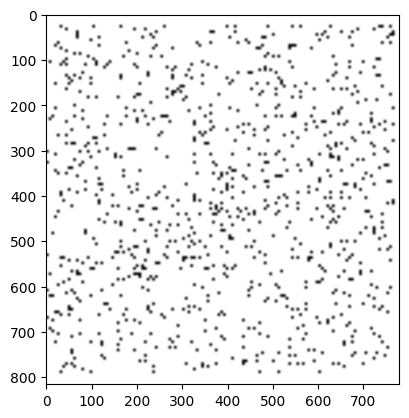

In [5]:
import cv2, numpy as np
import matplotlib.pyplot as plt

resim = cv2.imread('hough.png')
resim = cv2.cvtColor(resim, cv2.COLOR_BGR2RGB)
plt.imshow(resim)
plt.show()

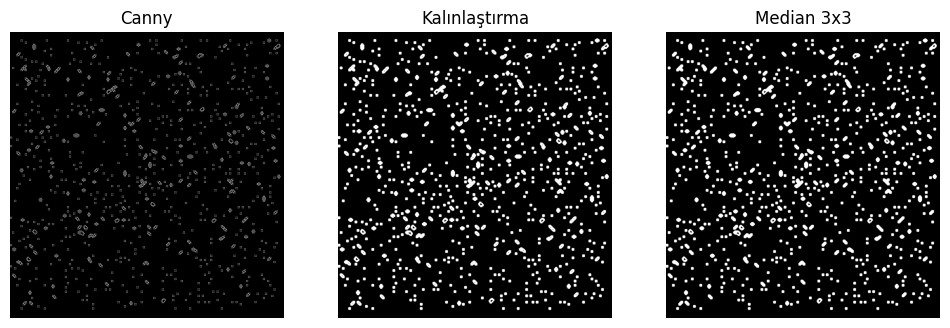

In [6]:
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)
kenar = cv2.Canny(gri, 50, 150)
kalin = cv2.dilate(kenar, np.ones((3, 3), np.uint8))
kenar_median = cv2.medianBlur(kalin, 3)

plt.figure(figsize=(12, 4))
for i, (r, b) in enumerate([(kenar, "Canny"), (kalin, "Kalınlaştırma"), (kenar_median, "Median 3x3")]):
    plt.subplot(1, 3, i + 1); plt.imshow(r, cmap="gray"); plt.title(b); plt.axis("off")
plt.show()

Doğru sayısı: 5


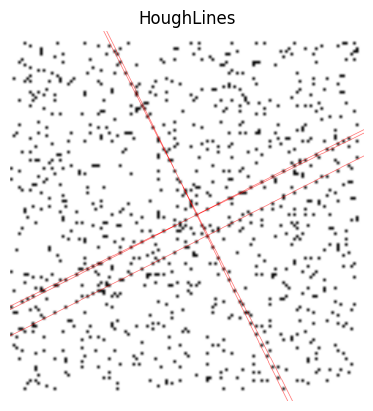

In [8]:
r1 = resim.copy()
doğrular = cv2.HoughLines(kenar_median, 1, np.pi / 180, 300)

if doğrular is not None:
    print("Doğru sayısı:", len(doğrular))
    for d in doğrular:
        rho, theta = d[0]
        a, b = np.cos(theta), np.sin(theta)
        x0, y0 = a * rho, b * rho
        p1 = (int(x0 - 2000 * b), int(y0 + 2000 * a))
        p2 = (int(x0 + 2000 * b), int(y0 - 2000 * a))
        cv2.line(r1, p1, p2, (0, 0, 255), 1)

plt.imshow(cv2.cvtColor(r1, cv2.COLOR_BGR2RGB)); plt.title("HoughLines"); plt.axis("off"); plt.show()

Çizgi sayısı: 13


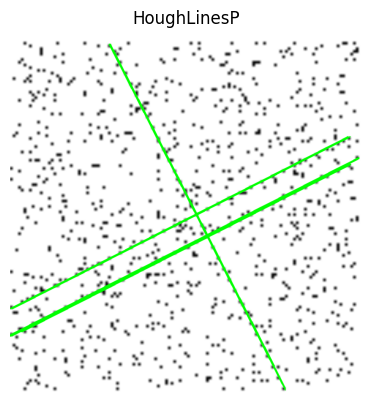

In [26]:
r2 = resim.copy()
parcalar = cv2.HoughLinesP(kenar_median, 1, np.pi / 180, 250, minLineLength=100, maxLineGap=100)

if parcalar is not None:
    print("Çizgi sayısı:", len(parcalar))
    for p in parcalar:
        x1, y1, x2, y2 = p.flatten()
        cv2.line(r2, (x1, y1), (x2, y2), (0, 255, 0), 2)
else:
    print("Çizgi bulunamadı")

plt.imshow(cv2.cvtColor(r2, cv2.COLOR_BGR2RGB)); plt.title("HoughLinesP"); plt.axis("off"); plt.show()